In [8]:
import os, sys, platform
print("Python:", sys.version)
print("Platform:", platform.platform())

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
    print("GPUs:", tf.config.list_physical_devices("GPU"))
    if not tf.config.list_physical_devices("GPU"):
        print("WARNING: No GPU detected. Training can still run on CPU, but may be slower.")
except Exception as e:
    print("TensorFlow import failed:", repr(e))
    raise

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, time, random, numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/Satellite_Land_Monitoring")
DIRS = {
    "models": PROJECT_DIR / "models",
    "checkpoints": PROJECT_DIR / "checkpoints",
    "datasets": PROJECT_DIR / "datasets",
    "results": PROJECT_DIR / "results",
    "predictions": PROJECT_DIR / "predictions",
    "dashboard": PROJECT_DIR / "dashboard",  # reserved for a future app
    "tfds_cache": PROJECT_DIR / "tfds_cache",
    "config": PROJECT_DIR / "config",
    "samples": PROJECT_DIR / "results" / "error_samples",
}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Drive mounted and project folders created.")
for name, p in DIRS.items():
    print(f"{name:12s} -> {p}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/Satellite_Land_Monitoring
Drive mounted and project folders created.
models       -> /content/drive/MyDrive/Satellite_Land_Monitoring/models
checkpoints  -> /content/drive/MyDrive/Satellite_Land_Monitoring/checkpoints
datasets     -> /content/drive/MyDrive/Satellite_Land_Monitoring/datasets
results      -> /content/drive/MyDrive/Satellite_Land_Monitoring/results
predictions  -> /content/drive/MyDrive/Satellite_Land_Monitoring/predictions
dashboard    -> /content/drive/MyDrive/Satellite_Land_Monitoring/dashboard
tfds_cache   -> /content/drive/MyDrive/Satellite_Land_Monitoring/tfds_cache
config       -> /content/drive/MyDrive/Satellite_Land_Monitoring/config
samples      -> /content/drive/MyDrive/Satellite_Land_Monitoring/results/error_samples


In [13]:
# Colab usually already includes TensorFlow and the required packages.
# Avoid upgrading TensorFlow unnecessarily, since that can break Colab compatibility.
import importlib.util, subprocess

required = ["tensorflow", "tensorflow_datasets", "sklearn", "matplotlib", "seaborn", "PIL", "pandas"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    package_map = {
        "tensorflow_datasets": "tensorflow-datasets",
        "sklearn": "scikit-learn",
        "PIL": "Pillow",
    }
    to_install = [package_map.get(x, x) for x in missing]
    print("Installing missing packages:", to_install)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])

import tensorflow as tf
import tensorflow_datasets as tfds
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("Pandas:", pd.__version__)
print("MobileNetV2 import: OK")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
Pandas: 2.2.3
MobileNetV2 import: OK


In [14]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TFDS_CACHE_DIR = str(DIRS["tfds_cache"])
DATA_CACHE_NPZ = DIRS["datasets"] / "eurosat_rgb_arrays.npz"
DATA_META_JSON = DIRS["datasets"] / "dataset_metadata.json"

CLASS_NAMES_EXPECTED = [
    "AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
    "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"
]

def save_dataset_cache(images, labels, names):
    np.savez_compressed(
        DATA_CACHE_NPZ,
        images=images,
        labels=labels.astype(np.int64),
        class_names=np.asarray(names, dtype=str)
    )
    metadata = {
        "dataset": "EuroSAT RGB",
        "image_count": int(len(images)),
        "image_shape": list(images.shape[1:]),
        "class_names": list(names),
        "source_used": SOURCE_USED
    }
    with open(DATA_META_JSON, "w") as f:
        json.dump(metadata, f, indent=2)
    print("Saved dataset cache to:", DATA_CACHE_NPZ)

if DATA_CACHE_NPZ.exists():
    print("Found cached dataset in Drive. Loading:", DATA_CACHE_NPZ)
    cached = np.load(DATA_CACHE_NPZ, allow_pickle=False)
    X_all = cached["images"]
    y_all = cached["labels"].astype(np.int64)
    class_names = cached["class_names"].astype(str).tolist()
    SOURCE_USED = "Google Drive NumPy cache"
else:
    X_all, y_all, class_names = None, None, None
    SOURCE_USED = None

    # First try a Hugging Face mirror to avoid the timeout-prone TFDS source.
    try:
        print("Trying EuroSAT RGB mirror from Hugging Face: timm/eurosat-rgb")
        try:
            from datasets import load_dataset
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
            from datasets import load_dataset

        hf_data = load_dataset("timm/eurosat-rgb", cache_dir=str(DIRS["datasets"] / "hf_cache"))
        print("Hugging Face splits:", list(hf_data.keys()))

        # Merge available splits so the notebook can create its own reproducible 70/15/15 split.
        all_images, all_labels = [], []
        label_feature = None
        for split_name in hf_data.keys():
            split = hf_data[split_name]
            if "image" not in split.column_names or "label" not in split.column_names:
                raise ValueError(
                    f"Unexpected columns in {split_name}: {split.column_names}. "
                    "Expected 'image' and 'label'."
                )
            label_feature = split.features.get("label", label_feature)
            for row in split:
                img = row["image"].convert("RGB")
                all_images.append(np.asarray(img, dtype=np.uint8))
                all_labels.append(row["label"])

        if label_feature is not None and getattr(label_feature, "names", None):
            class_names = list(label_feature.names)
        else:
            class_names = CLASS_NAMES_EXPECTED.copy()

        # If labels are strings, map them to the class index; if numeric, preserve IDs.
        if len(all_labels) and isinstance(all_labels[0], str):
            if set(all_labels).issubset(set(class_names)):
                y_all = np.asarray([class_names.index(x) for x in all_labels], dtype=np.int64)
            else:
                unique_names = sorted(set(all_labels))
                class_names = unique_names
                y_all = np.asarray([class_names.index(x) for x in all_labels], dtype=np.int64)
        else:
            y_all = np.asarray(all_labels, dtype=np.int64)

        X_all = np.stack(all_images).astype(np.uint8)

        # Validate class mapping. If source uses a different label order, use its declared names.
        if len(class_names) != len(np.unique(y_all)):
            raise ValueError(
                f"Class-name/label mismatch: {len(class_names)} names vs "
                f"{len(np.unique(y_all))} unique labels."
            )
        if set(np.unique(y_all).tolist()) != set(range(len(class_names))):
            raise ValueError(
                f"Labels are not contiguous from 0. Observed: {sorted(np.unique(y_all).tolist())}"
            )

        SOURCE_USED = "Hugging Face dataset mirror: timm/eurosat-rgb"
        save_dataset_cache(X_all, y_all, class_names)

    except Exception as hf_error:
        print("Hugging Face mirror failed:", repr(hf_error))
        print("Trying TensorFlow Datasets as a fallback. This may time out if madm.dfki.de is unreachable.")
        try:
            ds, info = tfds.load(
                "eurosat/rgb",
                split="train",
                as_supervised=True,
                with_info=True,
                data_dir=TFDS_CACHE_DIR,
                download=True,
                try_gcs=True
            )
            class_names = info.features["label"].names
            image_list, label_list = [], []
            for idx, (image, label) in enumerate(tfds.as_numpy(ds)):
                image_list.append(image)
                label_list.append(int(label))
                if (idx + 1) % 5000 == 0:
                    print(f"Read {idx + 1} images")
            X_all = np.stack(image_list).astype(np.uint8)
            y_all = np.asarray(label_list, dtype=np.int64)
            SOURCE_USED = "TensorFlow Datasets: eurosat/rgb"
            save_dataset_cache(X_all, y_all, class_names)
        except Exception as tfds_error:
            raise RuntimeError(
                "EuroSAT could not be downloaded from either source. "
                "Check that Colab has internet access, then rerun this cell. "
                "If a partial TFDS folder exists, this cell does not rely on it when "
                "the Hugging Face source succeeds.\n\n"
                f"Hugging Face error: {hf_error}\nTensorFlow Datasets error: {tfds_error}"
            )

print("Dataset source:", SOURCE_USED)
print("Images shape:", X_all.shape)
print("Labels shape:", y_all.shape)
print("Classes:", class_names)
print("Unique labels:", sorted(np.unique(y_all).tolist()))
assert len(class_names) == 10, f"Expected 10 classes, got {len(class_names)}"
assert len(X_all) == len(y_all)
assert set(np.unique(y_all).tolist()) == set(range(10))

Trying EuroSAT RGB mirror from Hugging Face: timm/eurosat-rgb


README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 55.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.4MB            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Hugging Face splits: ['train', 'validation', 'test']
Saved dataset cache to: /content/drive/MyDrive/Satellite_Land_Monitoring/datasets/eurosat_rgb_arrays.npz
Dataset source: Hugging Face dataset mirror: timm/eurosat-rgb
Images shape: (27000, 64, 64, 3)
Labels shape: (27000,)
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


,class_id,class_name,image_count
0,0,AnnualCrop,3000
1,1,Forest,3000
2,2,HerbaceousVegetation,3000
3,3,Highway,2500
4,4,Industrial,2500
5,5,Pasture,2000
6,6,PermanentCrop,2500
7,7,Residential,3000
8,8,River,2500
9,9,SeaLake,3000


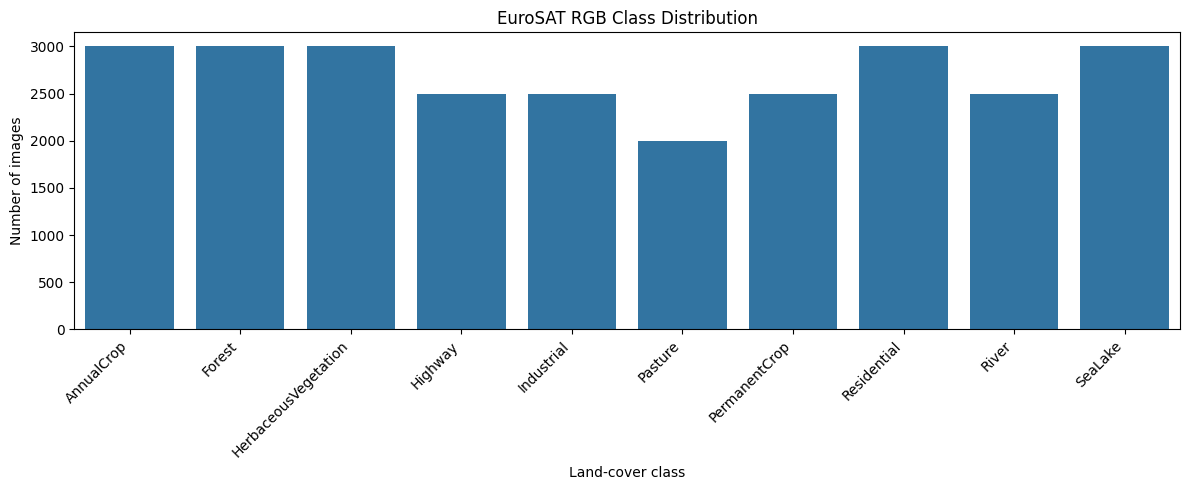

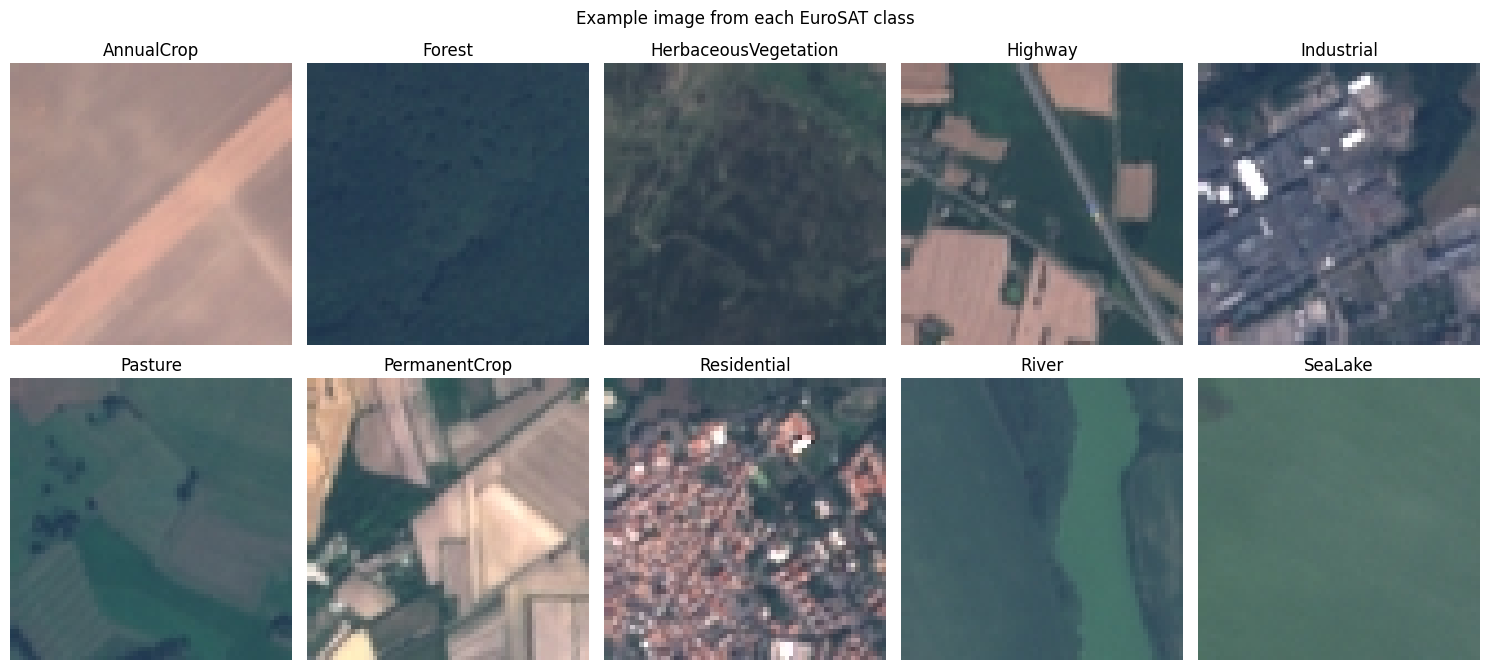

Original image dimensions: (64, 64, 3)
All exploration outputs saved under: /content/drive/MyDrive/Satellite_Land_Monitoring/results


In [15]:
counts = pd.Series(y_all).value_counts().sort_index()
distribution = pd.DataFrame({
    "class_id": range(len(class_names)),
    "class_name": class_names,
    "image_count": [int(counts.get(i, 0)) for i in range(len(class_names))]
})
display(distribution)
distribution.to_csv(DIRS["results"] / "class_distribution.csv", index=False)

plt.figure(figsize=(12, 5))
sns.barplot(data=distribution, x="class_name", y="image_count")
plt.title("EuroSAT RGB Class Distribution")
plt.xlabel("Land-cover class")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(DIRS["results"] / "class_distribution.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for class_id, ax in enumerate(axes.flat):
    ids = np.where(y_all == class_id)[0]
    if len(ids):
        image_idx = int(ids[0])
        ax.imshow(X_all[image_idx])
        ax.set_title(class_names[class_id])
    ax.axis("off")
plt.suptitle("Example image from each EuroSAT class")
plt.tight_layout()
plt.savefig(DIRS["results"] / "sample_images_by_class.png", dpi=160)
plt.show()

print("Original image dimensions:", X_all.shape[1:])
print("All exploration outputs saved under:", DIRS["results"])

In [16]:
indices = np.arange(len(y_all))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=y_all
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=y_all[temp_idx]
)

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

split_summary = {
    "seed": SEED,
    "train_count": int(len(train_idx)),
    "validation_count": int(len(val_idx)),
    "test_count": int(len(test_idx)),
    "total_count": int(len(indices)),
    "train_fraction": float(len(train_idx) / len(indices)),
    "validation_fraction": float(len(val_idx) / len(indices)),
    "test_fraction": float(len(test_idx) / len(indices)),
    "class_names": class_names,
}
with open(DIRS["config"] / "split_summary.json", "w") as f:
    json.dump(split_summary, f, indent=2)

print(split_summary)
for split_name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    per_class = np.bincount(labels, minlength=len(class_names))
    print(f"{split_name:10s}: {len(labels):5d} images | per-class counts: {per_class.tolist()}")
assert all(np.bincount(s, minlength=10).min() > 0 for s in [y_train, y_val, y_test])

{'seed': 42, 'train_count': 18900, 'validation_count': 4050, 'test_count': 4050, 'total_count': 27000, 'train_fraction': 0.7, 'validation_fraction': 0.15, 'test_fraction': 0.15, 'class_names': ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']}
Train     : 18900 images | per-class counts: [2100, 2100, 2100, 1750, 1750, 1400, 1750, 2100, 1750, 2100]
Validation:  4050 images | per-class counts: [450, 450, 450, 375, 375, 300, 375, 450, 375, 450]
Test      :  4050 images | per-class counts: [450, 450, 450, 375, 375, 300, 375, 450, 375, 450]


In [17]:
IMG_SIZE = 224
BATCH_SIZE = 32  # Reduce to 16 if GPU memory is limited.
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(min(len(images), 10000), seed=SEED, reshuffle_each_iteration=True)
    def resize_image(image, label):
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), antialias=True)
        image = tf.cast(image, tf.float32)  # keep pixel range 0..255; model handles scaling
        label = tf.cast(label, tf.int32)
        return image, label
    ds = ds.map(resize_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val, training=False)
test_ds = make_dataset(X_test, y_test, training=False)
print("Data pipelines ready.")

Data pipelines ready.


In [18]:
NUM_CLASSES = len(class_names)
BASE_MODEL_NAME = "MobileNetV2"
INITIAL_LR = 1e-3
FINETUNE_LR = 1e-5
DROPOUT_RATE = 0.30
FINE_TUNE_LAST_N_LAYERS = 30

INITIAL_BEST_PATH = DIRS["models"] / "mobilenetv2_transfer_best.keras"
FINETUNE_BEST_PATH = DIRS["models"] / "mobilenetv2_finetuned_best.keras"
LATEST_CHECKPOINT_PATH = DIRS["checkpoints"] / "mobilenetv2_latest.keras"
CLASS_NAMES_PATH = DIRS["config"] / "class_names.json"

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="training_augmentation")

base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="satellite_rgb")
x = augmentation(inputs)
x = layers.Rescaling(scale=1./127.5, offset=-1, name="mobilenetv2_preprocessing")(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(DROPOUT_RATE, name="dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="land_cover_predictions")(x)
model = models.Model(inputs, outputs, name="eurosat_mobilenetv2")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()
print("Trainable parameters:", sum(np.prod(v.shape) for v in model.trainable_weights))
print("Non-trainable parameters:", sum(np.prod(v.shape) for v in model.non_trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "eurosat_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ satellite_rgb (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocessing       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ land_cover_predictions (Dense)  │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable parameters: 12810
Non-trainable parameters: 2257984


In [19]:
HEAD_EPOCHS = 10  # Increase if needed; actual time depends on GPU/runtime.
head_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(INITIAL_BEST_PATH),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(LATEST_CHECKPOINT_PATH),
        monitor="val_loss",
        save_best_only=False,
        save_weights_only=False,
        verbose=0
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(DIRS["results"] / "head_training_history.csv"))
]

head_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=head_callbacks
)

model.save(DIRS["models"] / "mobilenetv2_transfer_final.keras")
print("Best initial model:", INITIAL_BEST_PATH)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)

Epoch 1/10
352/591 ━━━━━━━━━━━━━━━━━━━━ 14s 62ms/step - accuracy: 0.6763 - loss: 0.9844

423/591 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.6987 - loss: 0.9152

591/591 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.7350 - loss: 0.8033
Epoch 1: val_loss improved from None to 0.24305, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 66s 91ms/step - accuracy: 0.8346 - loss: 0.4955 - val_accuracy: 0.9151 - val_loss: 0.2431 - learning_rate: 0.0010
Epoch 2/10
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8957 - loss: 0.2948
Epoch 2: val_loss improved from 0.24305 to 0.21717, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 62s 105ms/step - accuracy: 0.9000 - loss: 0.2862 - val_accuracy: 0.9294 - val_loss: 0.2172 - learning_rate: 0.


Epoch 3: val_loss improved from 0.21717 to 0.20044, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 51s 86ms/step - accuracy: 0.9089 - loss: 0.2543 - val_accuracy: 0.9323 - val_loss: 0.2004 - learning_rate: 0.0010
Epoch 4/10
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9158 - loss: 0.2409
Epoch 4: val_loss improved from 0.20044 to 0.19298, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 4: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 45s 75ms/step - accuracy: 0.9161 - loss: 0.2431 - val_accuracy: 0.9348 - val_loss: 0.1930 - learning_rate: 0.0010
Epoch 5/10
229/591 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.

590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9211 - loss: 0.2305


Epoch 5: val_loss improved from 0.19298 to 0.18210, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 5: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 85s 80ms/step - accuracy: 0.9180 - loss: 0.2384 - val_accuracy: 0.9398 - val_loss: 0.1821 - learning_rate: 0.0010
Epoch 6/10
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9207 - loss: 0.2264
Epoch 6: val_loss did not improve from 0.18210
591/591 ━━━━━━━━━━━━━━━━━━━━ 79s 75ms/step - accuracy: 0.9212 - loss: 0.2269 - val_accuracy: 0.9368 - val_loss: 0.1856 - learning_rate: 0.0010
Epoch 7/10
374/591 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step - accuracy: 0.9231 - loss: 0.2230

590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9233 - loss: 0.2213
Epoch 7: val_loss improved from 0.18210 to 0.17715, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 7: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 87s 83ms/step - accuracy: 0.9212 - loss: 0.2249 - val_accuracy: 0.9420 - val_loss: 0.1771 - learning_rate: 0.0010
Epoch 8/10
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9236 - loss: 0.2211
Epoch 8: val_loss improved from 0.17715 to 0.17662, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras

Epoch 8: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 82s 83ms/step - accuracy: 0.9257 - loss: 0.2136 - val_accuracy: 0.9412 - val_loss: 0.1766 - learning_rate: 


Epoch 9: val_loss did not improve from 0.17662
591/591 ━━━━━━━━━━━━━━━━━━━━ 46s 78ms/step - accuracy: 0.9239 - loss: 0.2275 - val_accuracy: 0.9323 - val_loss: 0.1949 - learning_rate: 0.0010
Epoch 10/10
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9249 - loss: 0.2146
Epoch 10: val_loss did not improve from 0.17662

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
591/591 ━━━━━━━━━━━━━━━━━━━━ 80s 74ms/step - accuracy: 0.9244 - loss: 0.2167 - val_accuracy: 0.9393 - val_loss: 0.1884 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 8.
Best initial model: /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_transfer_best.keras
Latest checkpoint: /content/drive/MyDrive/Satellite_Land_Monitoring/checkpoints/mobilenetv2_latest.keras


In [20]:
# Start fine-tuning from the best head model when it exists.
if INITIAL_BEST_PATH.exists():
    model = tf.keras.models.load_model(INITIAL_BEST_PATH)
    # The loaded model's backbone is the nested layer named "mobilenetv2_1.00_224".
    base_model = model.get_layer("mobilenetv2_1.00_224")
else:
    print("Initial best model not found; continuing with current in-memory model.")

base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAST_N_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FINETUNE_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable backbone layers:", sum(1 for l in base_model.layers if l.trainable))
print("Total trainable tensors:", len(model.trainable_weights))
model.summary()

Trainable backbone layers: 19
Total trainable tensors: 12


Model: "eurosat_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ satellite_rgb (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocessing       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ land_cover_predictions (Dense)  │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 1,523,530 (5.81 MB)

 Non-trainable params: 747,264 (2.85 MB)

In [21]:
FINETUNE_EPOCHS = 15  # Adjust to available runtime/GPU memory.
finetune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(FINETUNE_BEST_PATH),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(LATEST_CHECKPOINT_PATH),
        monitor="val_loss",
        save_best_only=False,
        save_weights_only=False,
        verbose=0
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=2, min_lr=1e-8, verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(DIRS["results"] / "finetune_training_history.csv"))
]

finetune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINETUNE_EPOCHS,
    callbacks=finetune_callbacks
)

model.save(DIRS["models"] / "mobilenetv2_finetuned_final.keras")
print("Best fine-tuned model:", FINETUNE_BEST_PATH)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)

Epoch 1/15
414/591 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.9330 - loss: 0.1984

591/591 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9330 - loss: 0.1981
Epoch 1: val_loss improved from None to 0.16538, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 56s 85ms/step - accuracy: 0.9333 - loss: 0.1965 - val_accuracy: 0.9452 - val_loss: 0.1654 - learning_rate: 1.0000e-05
Epoch 2/15
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9360 - loss: 0.1834
Epoch 2: val_loss improved from 0.16538 to 0.16048, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 52s 87ms/step - accuracy: 0.9388 - loss: 0.1797 - val_accuracy: 0.9442 - val_loss: 0.1605 - learning_r

590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9527 - loss: 0.1396
Epoch 4: val_loss improved from 0.14564 to 0.13819, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras

Epoch 4: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 49s 83ms/step - accuracy: 0.9497 - loss: 0.1473 - val_accuracy: 0.9548 - val_loss: 0.1382 - learning_rate: 1.0000e-05
Epoch 5/15
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9552 - loss: 0.1281
Epoch 5: val_loss improved from 0.13819 to 0.13115, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras

Epoch 5: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 50s 84ms/step - accuracy: 0.9542 - loss: 0.1319 - val_accuracy: 0.9560 - val_loss: 0.1311 - learnin

590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9630 - loss: 0.1055
Epoch 8: val_loss improved from 0.12319 to 0.12160, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras

Epoch 8: finished saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 49s 82ms/step - accuracy: 0.9616 - loss: 0.1089 - val_accuracy: 0.9627 - val_loss: 0.1216 - learning_rate: 1.0000e-05
Epoch 9/15
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9636 - loss: 0.1069
Epoch 9: val_loss did not improve from 0.12160
591/591 ━━━━━━━━━━━━━━━━━━━━ 84s 86ms/step - accuracy: 0.9633 - loss: 0.1066 - val_accuracy: 0.9578 - val_loss: 0.1240 - learning_rate: 1.0000e-05
Epoch 10/15
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9651 - loss: 0.0976
Epoch 10: val_loss improved from 0.12160 to 0.11656, saving model to /content/drive/MyDrive/Satellite_Land_Monitoring/models/mo

In [22]:
def load_recovery_model(prefer_finetuned=True):
    candidates = []
    if prefer_finetuned:
        candidates += [FINETUNE_BEST_PATH, LATEST_CHECKPOINT_PATH, INITIAL_BEST_PATH]
    else:
        candidates += [INITIAL_BEST_PATH, LATEST_CHECKPOINT_PATH, FINETUNE_BEST_PATH]
    for path in candidates:
        if path.exists():
            print("Loading recovery model:", path)
            return tf.keras.models.load_model(path)
    raise FileNotFoundError(
        "No model checkpoint found in Drive. Run the training cells first."
    )

# Set to True to load the best fine-tuned model if it exists.
# This cell is safe to run after a runtime restart, once paths and imports are defined.
model = load_recovery_model(prefer_finetuned=True)
print("Recovery model loaded.")

Loading recovery model: /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
Recovery model loaded.


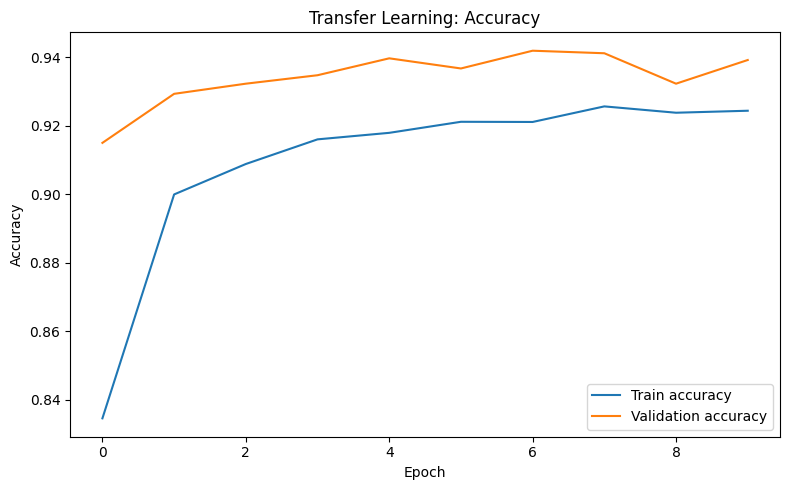

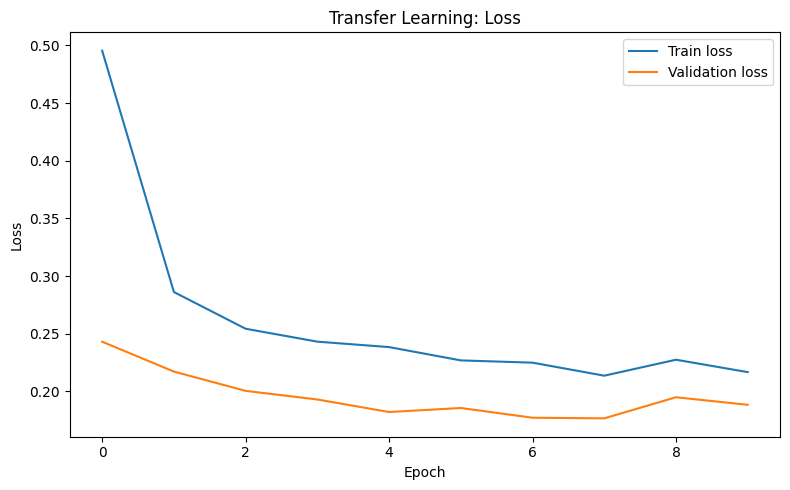

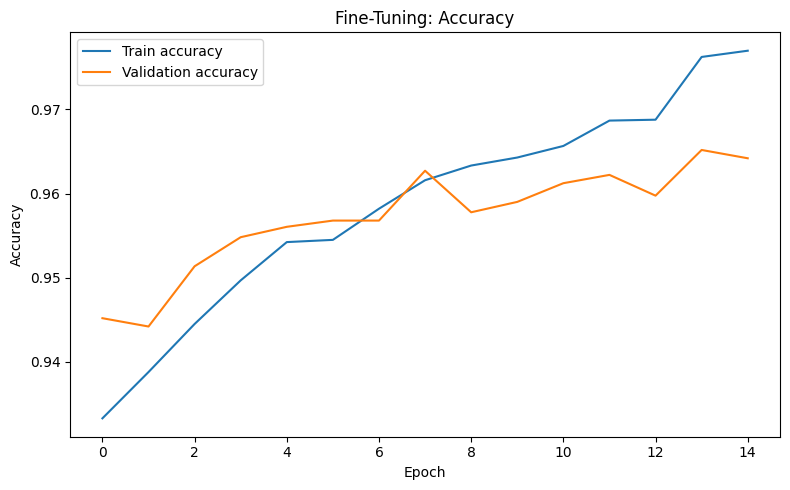

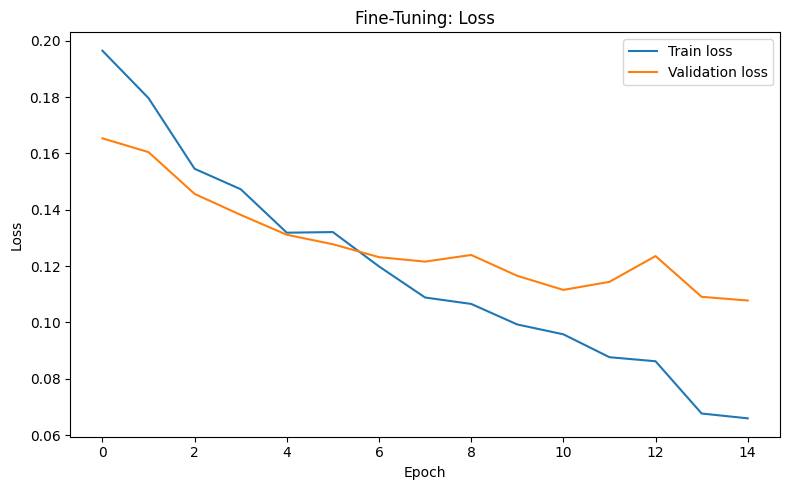

In [23]:
def plot_history_csv(csv_path, title_prefix, output_prefix):
    if not csv_path.exists():
        print("History CSV not found:", csv_path)
        return
    hist = pd.read_csv(csv_path)
    if hist.empty:
        print("History CSV is empty:", csv_path)
        return
    if "accuracy" in hist and "val_accuracy" in hist:
        plt.figure(figsize=(8, 5))
        plt.plot(hist["accuracy"], label="Train accuracy")
        plt.plot(hist["val_accuracy"], label="Validation accuracy")
        plt.title(f"{title_prefix}: Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.tight_layout()
        plt.savefig(DIRS["results"] / f"{output_prefix}_accuracy.png", dpi=160)
        plt.show()
    if "loss" in hist and "val_loss" in hist:
        plt.figure(figsize=(8, 5))
        plt.plot(hist["loss"], label="Train loss")
        plt.plot(hist["val_loss"], label="Validation loss")
        plt.title(f"{title_prefix}: Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.tight_layout()
        plt.savefig(DIRS["results"] / f"{output_prefix}_loss.png", dpi=160)
        plt.show()

plot_history_csv(DIRS["results"] / "head_training_history.csv", "Transfer Learning", "head")
plot_history_csv(DIRS["results"] / "finetune_training_history.csv", "Fine-Tuning", "finetune")

In [24]:
if FINETUNE_BEST_PATH.exists():
    BEST_MODEL_PATH = FINETUNE_BEST_PATH
elif INITIAL_BEST_PATH.exists():
    BEST_MODEL_PATH = INITIAL_BEST_PATH
else:
    raise FileNotFoundError("No best model found. Run training first.")

model = tf.keras.models.load_model(BEST_MODEL_PATH)
print("Evaluating model:", BEST_MODEL_PATH)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

test_accuracy_sklearn = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
precision_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

evaluation = {
    "model_path": str(BEST_MODEL_PATH),
    "test_loss": float(test_loss),
    "test_accuracy_keras": float(test_accuracy),
    "test_accuracy_sklearn": float(test_accuracy_sklearn),
    "precision_macro": float(precision_macro),
    "recall_macro": float(recall_macro),
    "f1_macro": float(f1_macro),
    "precision_weighted": float(precision_weighted),
    "recall_weighted": float(recall_weighted),
    "f1_weighted": float(f1_weighted),
    "test_count": int(len(y_test)),
    "class_names": class_names,
}
print(json.dumps(evaluation, indent=2))
with open(DIRS["results"] / "evaluation_summary.json", "w") as f:
    json.dump(evaluation, f, indent=2)

Evaluating model: /content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras
127/127 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.9644 - loss: 0.1061
127/127 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step
{
  "model_path": "/content/drive/MyDrive/Satellite_Land_Monitoring/models/mobilenetv2_finetuned_best.keras",
  "test_loss": 0.10612525045871735,
  "test_accuracy_keras": 0.9644444584846497,
  "test_accuracy_sklearn": 0.9644444444444444,
  "precision_macro": 0.9632386777155111,
  "recall_macro": 0.9628444444444444,
  "f1_macro": 0.962859515311148,
  "precision_weighted": 0.9647202406106395,
  "recall_weighted": 0.9644444444444444,
  "f1_weighted": 0.9644006777191246,
  "test_count": 4050,
  "class_names": [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
  ]
}


,precision,recall,f1-score,support
AnnualCrop,0.950324,0.977778,0.963855,450.000000
Forest,0.971616,0.988889,0.980176,450.000000
HerbaceousVegetation,0.972028,0.926667,0.948805,450.000000
Highway,0.943243,0.930667,0.936913,375.000000
Industrial,0.976378,0.992000,0.984127,375.000000
Pasture,0.952055,0.926667,0.939189,300.000000
PermanentCrop,0.921519,0.970667,0.945455,375.000000
Residential,0.993304,0.988889,0.991091,450.000000
River,0.954178,0.944000,0.949062,375.000000
SeaLake,0.997743,0.982222,0.989922,450.000000


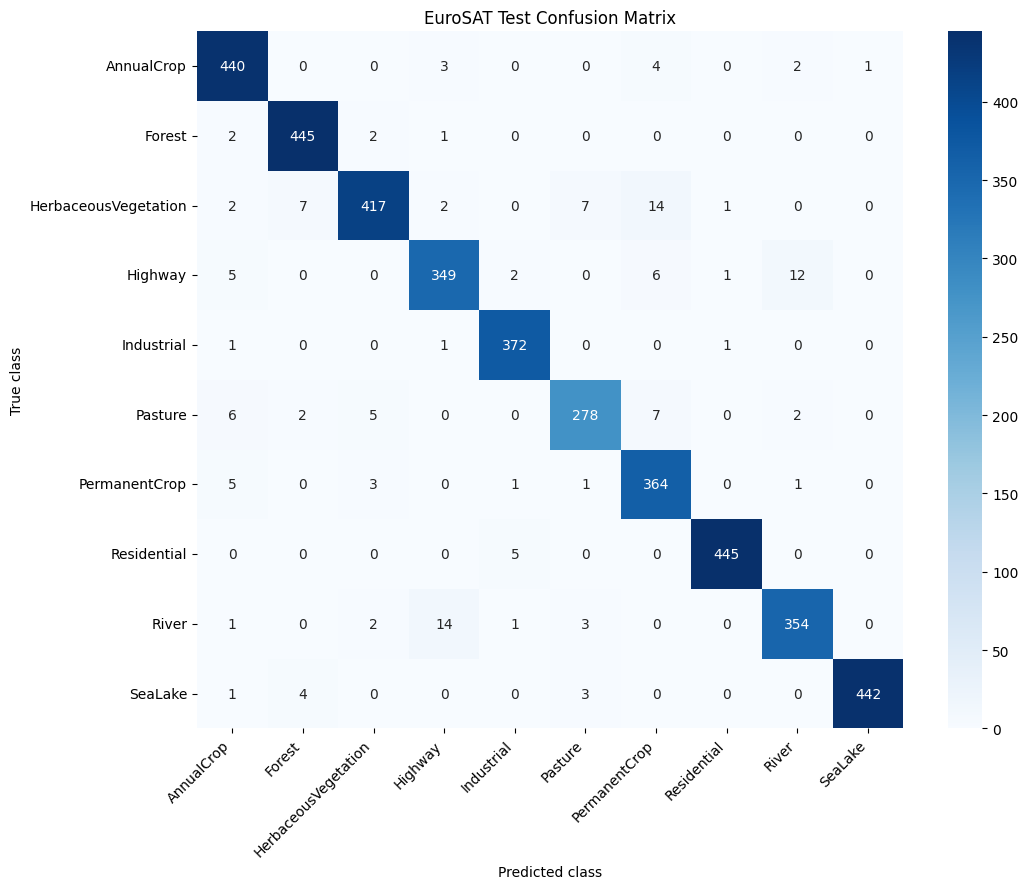

In [25]:
report_dict = classification_report(
    y_test, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=class_names, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df)
report_df.to_csv(DIRS["results"] / "classification_report.csv", index=True)

cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.to_csv(DIRS["results"] / "confusion_matrix.csv")

plt.figure(figsize=(11, 9))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("EuroSAT Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(DIRS["results"] / "confusion_matrix.png", dpi=180)
plt.show()

Misclassified: 144 of 4050


,test_position,true_class,predicted_class,confidence,true_class_probability
0,17,Highway,River,0.927203,0.072796
1,24,HerbaceousVegetation,PermanentCrop,0.328558,0.187603
2,43,HerbaceousVegetation,Pasture,0.997584,0.000901
3,47,HerbaceousVegetation,PermanentCrop,0.835627,0.140370
4,61,Industrial,AnnualCrop,0.867974,0.124366
5,82,Highway,Industrial,0.675382,0.324429
6,142,HerbaceousVegetation,PermanentCrop,0.611036,0.369826
7,213,HerbaceousVegetation,Forest,0.923885,0.075283
8,255,Pasture,AnnualCrop,0.747338,0.244377
9,272,River,Highway,0.759431,0.239613


,true_class,predicted_class,count
34,River,Highway,14
11,HerbaceousVegetation,PermanentCrop,14
17,Highway,River,12
10,HerbaceousVegetation,Pasture,7
8,HerbaceousVegetation,Forest,7
24,Pasture,PermanentCrop,7
15,Highway,PermanentCrop,6
21,Pasture,AnnualCrop,6
26,PermanentCrop,AnnualCrop,5
31,Residential,Industrial,5


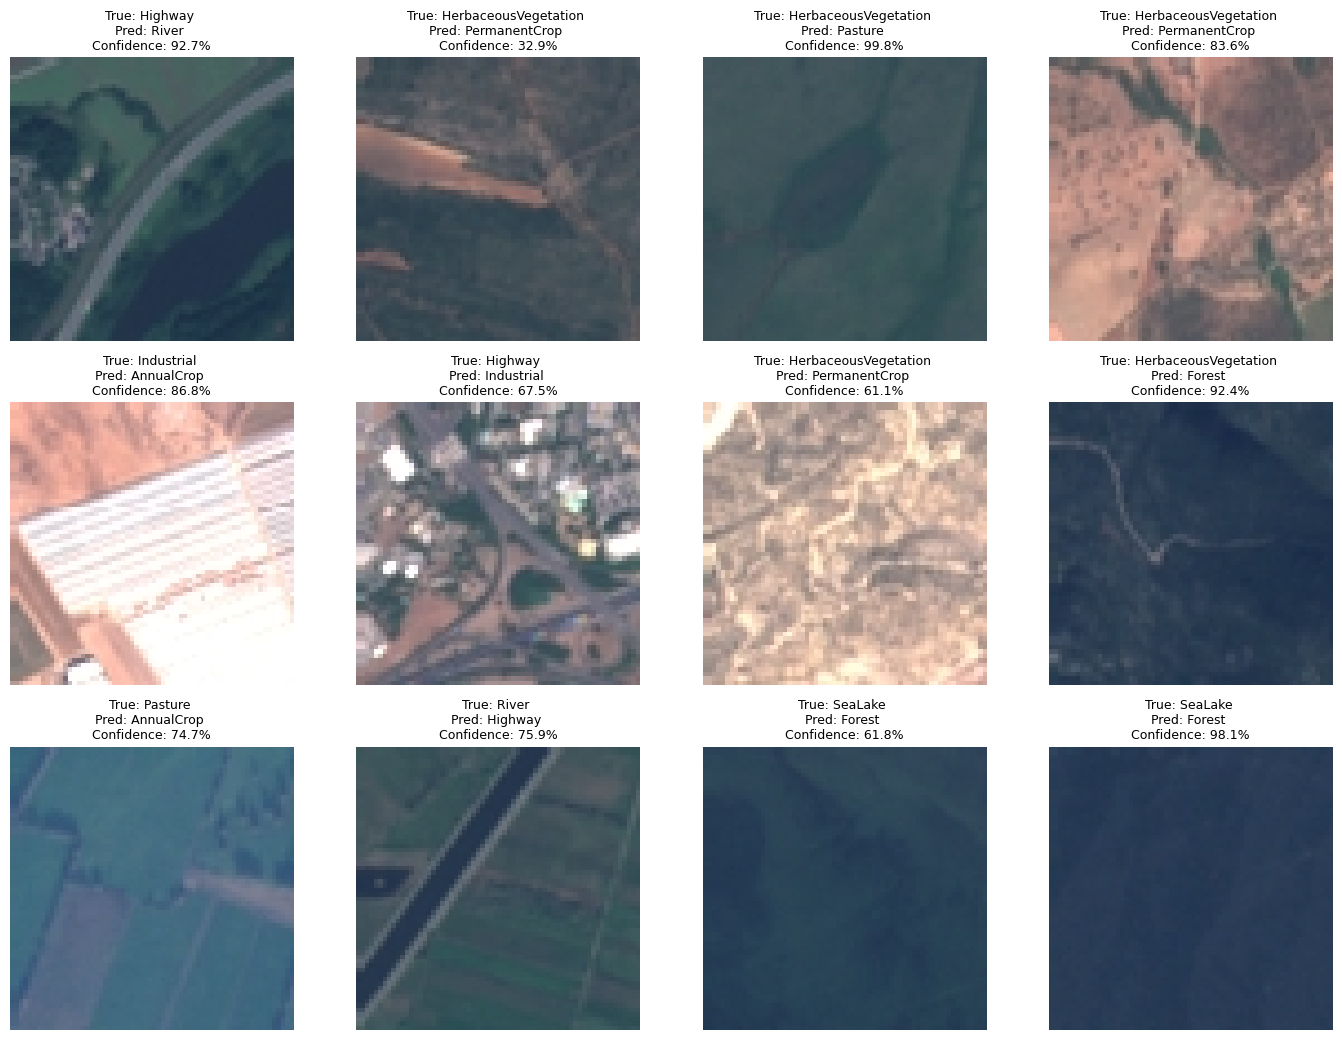

Common causes of confusion may include visually similar land-cover patterns, mixed land cover, and low spatial resolution.


In [31]:
wrong_positions = np.where(y_pred != y_test)[0]
error_rows = []
for pos in wrong_positions:
    error_rows.append({
        "test_position": int(pos),
        "true_class": class_names[int(y_test[pos])],
        "predicted_class": class_names[int(y_pred[pos])],
        "confidence": float(np.max(probabilities[pos])),
        "true_class_probability": float(probabilities[pos, int(y_test[pos])]),
    })
errors_df = pd.DataFrame(error_rows)
errors_df.to_csv(DIRS["results"] / "misclassification_errors.csv", index=False)
print("Misclassified:", len(wrong_positions), "of", len(y_test))
display(errors_df.head(20))

if not errors_df.empty:
    pair_counts = (
        errors_df.groupby(["true_class", "predicted_class"]
    ).size().reset_index(name="count")
    .sort_values("count", ascending=False)
    )
    pair_counts.to_csv(DIRS["results"] / "most_confused_class_pairs.csv", index=False)
    display(pair_counts.head(15))

    n_show = min(12, len(wrong_positions))
    selected_positions = wrong_positions[:n_show]
    fig, axes = plt.subplots((n_show + 3)//4, 4, figsize=(14, 3.5*((n_show + 3)//4)))
    axes = np.array(axes).reshape(-1)
    for ax, pos in zip(axes, selected_positions):
        ax.imshow(X_test[pos])
        ax.set_title(
            f"True: {class_names[int(y_test[pos])]} \n"
            f"Pred: {class_names[int(y_pred[pos])]} \n"
            f"Confidence: {np.max(probabilities[pos]):.1%}",
            fontsize=9
        )
        ax.axis("off")
        out_img = DIRS["samples"] / f"misclassified_{int(pos)}.png"
        Image.fromarray(X_test[pos]).save(out_img)
    for ax in axes[n_show:]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(DIRS["results"] / "misclassified_examples.png", dpi=160)
    plt.show()
else:
    print("No test errors found in this run. Verify the metrics and split counts above.")

print("Common causes of confusion may include visually similar land-cover patterns, mixed land cover, and low spatial resolution.")

In [32]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

def predict_satellite_image(image_path, model=None, save_json=True):
    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f"Image file not found: {image_path}")
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        raise ValueError("Unsupported format. Use JPG, JPEG, or PNG.")
    if model is None:
        if not Path(BEST_MODEL_PATH).exists():
            raise FileNotFoundError(f"Model checkpoint not found: {BEST_MODEL_PATH}")
        model = tf.keras.models.load_model(BEST_MODEL_PATH)
    try:
        pil_image = Image.open(image_path).convert("RGB")
    except (UnidentifiedImageError, OSError) as exc:
        raise ValueError(f"Could not open a valid image: {image_path}") from exc

    display_image = pil_image.copy()
    resized = pil_image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
    arr = np.asarray(resized, dtype=np.float32)
    batch = np.expand_dims(arr, axis=0)
    probs = model.predict(batch, verbose=0)[0]
    top_ids = np.argsort(probs)[::-1][:3]
    result = {
        "image_path": str(image_path),
        "predicted_class": class_names[int(top_ids[0])],
        "confidence": float(probs[top_ids[0]]),
        "top_3": [
            {"class": class_names[int(i)], "confidence": float(probs[i])}
            for i in top_ids
        ],
        "model_path": str(BEST_MODEL_PATH),
    }

    plt.figure(figsize=(6, 5))
    plt.imshow(display_image)
    plt.axis("off")
    plt.title(f"Prediction: {result['predicted_class']} ({result['confidence']:.1%})")
    plt.show()
    print("Top 3 predictions:")
    for item in result["top_3"]:
        print(f"  {item['class']}: {item['confidence']:.2%}")

    if save_json:
        timestamp = time.strftime("%Y%m%d_%H%M%S")
        output_path = DIRS["predictions"] / f"prediction_{timestamp}.json"
        with open(output_path, "w") as f:
            json.dump(result, f, indent=2)
        print("Prediction JSON saved to:", output_path)
    return result

# Example:
IMAGE_PATH = DIRS["predictions"] / "new_satellite.jpg"
# Add your image to this Drive location, then run:
# prediction_result = predict_satellite_image(IMAGE_PATH, model=model)
print("Place an image at:", IMAGE_PATH)

Place an image at: /content/drive/MyDrive/Satellite_Land_Monitoring/predictions/new_satellite.jpg


In [33]:
important_paths = [
    DATA_CACHE_NPZ,
    CLASS_NAMES_PATH,
    DIRS["results"] / "class_distribution.png",
    DIRS["results"] / "evaluation_summary.json",
    DIRS["results"] / "classification_report.csv",
    DIRS["results"] / "confusion_matrix.png",
    BEST_MODEL_PATH,
]
verification = []
for path in important_paths:
    verification.append({
        "path": str(path),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() and path.is_file() else None,
    })
verification_df = pd.DataFrame(verification)
display(verification_df)
verification_df.to_csv(DIRS["results"] / "drive_export_verification.csv", index=False)

,path,exists,size_bytes
0,/content/drive/MyDrive/Satellite_Land_Monitori...,True,207782233
1,/content/drive/MyDrive/Satellite_Land_Monitori...,True,158
2,/content/drive/MyDrive/Satellite_Land_Monitori...,True,78938
3,/content/drive/MyDrive/Satellite_Land_Monitori...,True,693
4,/content/drive/MyDrive/Satellite_Land_Monitori...,True,976
5,/content/drive/MyDrive/Satellite_Land_Monitori...,True,159447
6,/content/drive/MyDrive/Satellite_Land_Monitori...,True,21874605


In [34]:
experiment_config = {
    "project": "Satellite Image Classification for Smart Land Monitoring",
    "dataset": "EuroSAT RGB",
    "dataset_source": "https://www.tensorflow.org/datasets/catalog/eurosat",
    "model_architecture": BASE_MODEL_NAME,
    "pretrained_weights": "ImageNet weights provided by tf.keras.applications.MobileNetV2",
    "image_size": [IMG_SIZE, IMG_SIZE],
    "random_seed": SEED,
    "split": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "split_counts": {
        "train": int(len(X_train)),
        "validation": int(len(X_val)),
        "test": int(len(X_test)),
    },
    "batch_size": BATCH_SIZE,
    "initial_learning_rate": INITIAL_LR,
    "fine_tuning_learning_rate": FINETUNE_LR,
    "head_epochs_configured": HEAD_EPOCHS,
    "fine_tune_epochs_configured": FINETUNE_EPOCHS,
    "fine_tune_last_n_layers": FINE_TUNE_LAST_N_LAYERS,
    "augmentation": ["horizontal flip", "small rotation", "small zoom; training only"],
    "best_model_path": str(BEST_MODEL_PATH),
    "evaluation": evaluation,
    "runtime_tensorflow_version": tf.__version__,
    "notes": [
        "Actual metrics are produced by executing this notebook.",
        "GPU operations/software environments may cause small numerical differences.",
        "No Streamlit application is created in this phase."
    ],
}
with open(DIRS["config"] / "experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)
print("Experiment configuration saved:", DIRS["config"] / "experiment_config.json")
print("Project complete. Review results in:", DIRS["results"])

Experiment configuration saved: /content/drive/MyDrive/Satellite_Land_Monitoring/config/experiment_config.json
Project complete. Review results in: /content/drive/MyDrive/Satellite_Land_Monitoring/results


Saving sat.jpeg to sat.jpeg
Predicted Class: SeaLake
Confidence: 98.05 %


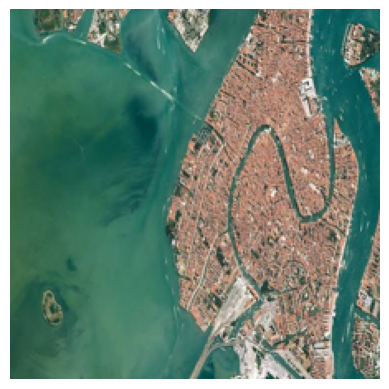

In [35]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload satellite image
uploaded = files.upload()
img_path = next(iter(uploaded))

# Load and resize image
img = Image.open(img_path).convert("RGB").resize((224, 224))

# Predict using your trained model
img_array = np.expand_dims(np.array(img), axis=0)
pred = model.predict(img_array, verbose=0)[0]

# Display prediction
index = np.argmax(pred)
print("Predicted Class:", class_names[index])
print("Confidence:", round(float(pred[index]) * 100, 2), "%")

plt.imshow(img)
plt.axis("off")
plt.show()